# Task 5: Results Visualisation & Project Delivery

## Retail Sales Forecasting with LSTM

### Objective
This notebook presents the model evaluation results, compares the LSTM models with a naive baseline, visualises prediction errors, and documents the main findings and limitations.

### Project workflow
1. Exploratory Data Analysis
2. Data Preprocessing
3. LSTM Model Development
4. Model Evaluation and Optimisation
5. Results Visualisation and Project Delivery

In [1]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd()

# Handle running from either the project root or notebooks/
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Figures directory:", FIGURES_DIR)


Project root: c:\Users\franc\OneDrive\Desktop\DATA SCIENCE\Predictive Analytics on Retail Sales\retail-sales-lstm-forecasting
Figures directory: c:\Users\franc\OneDrive\Desktop\DATA SCIENCE\Predictive Analytics on Retail Sales\retail-sales-lstm-forecasting\outputs\figures


,Model,MAE,RMSE
0,Naive Baseline,165347.39,227751.17
1,LSTM - 32 Units,96164.54,153011.12
2,LSTM - 64 Units,93789.06,149901.76


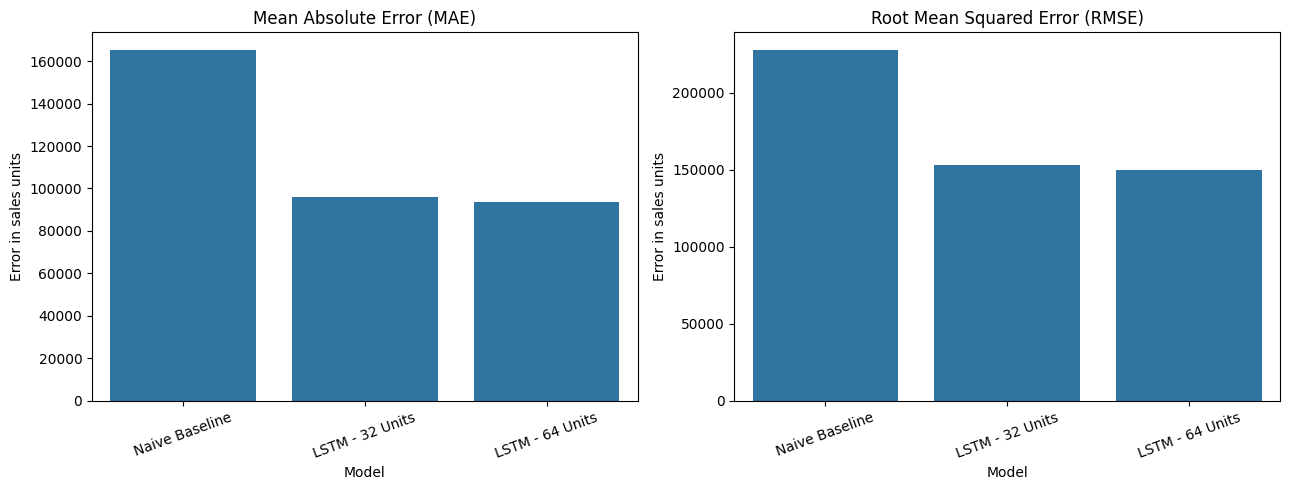

In [2]:

# Model evaluation results from Task 4
# Confirm these values against your latest Task 4 output.

results = pd.DataFrame({
    "Model": [
        "Naive Baseline",
        "LSTM - 32 Units",
        "LSTM - 64 Units"
    ],
    "MAE": [
        165347.39,
        96164.54,
        93789.06
    ],
    "RMSE": [
        227751.17,
        153011.12,
        149901.76
    ]
})

display(results.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(data=results, x="Model", y="MAE", ax=axes[0])
axes[0].set_title("Mean Absolute Error (MAE)")
axes[0].set_ylabel("Error in sales units")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(data=results, x="Model", y="RMSE", ax=axes[1])
axes[1].set_title("Root Mean Squared Error (RMSE)")
axes[1].set_ylabel("Error in sales units")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "11_model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


## Key Findings

- The naive baseline provides a reference point for evaluating the LSTM models.
- Both LSTM models achieved lower MAE and RMSE than the naive baseline in the evaluation results.
- The 64-unit LSTM achieved the lowest test MAE and RMSE among the three models in the results used for this comparison.
- The results suggest that the LSTM models captured useful patterns in the daily sales time series.

## Limitations

- The dataset contains sales from multiple stores and product families aggregated into a single daily series. Individual store and product-level forecasts are not evaluated here.
- Missing dates were filled with zero sales during preprocessing. These values are assumptions, not observed sales.
- The comparison uses rolling one-day-ahead predictions, where previous actual observations are available. Performance may differ for forecasts made many days into the future.
- Model performance on this historical test period does not guarantee future performance.
- The results depend on the selected model architecture, training settings, and evaluation period.

## Conclusion

The LSTM models outperformed the naive baseline on the evaluation metrics used in this experiment. The 64-unit model had the lowest test errors in the reported comparison, while model selection should also consider validation performance and the risk of overfitting.

This project demonstrates an end-to-end time-series forecasting workflow, from exploratory analysis and preprocessing to model evaluation and results visualisation.